In [2]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

In [3]:
def multi_scale(t, X, kappa, gamma, alpha_k, beta_k, g=0.0):
    """
    Modèle multi-échelles continu déterministe

    État:
        X[0] = delta : écart prix - valeur fondamentale
        X[1:] = M_1, ... M_k : facteurs de tendance
    """

    delta = X[0]
    M = X[1:]

    trend = np.sum(beta_k * np.tanh(gamma * M))

    ddelta = -kappa * delta + trend - g

    dM = -alpha_k * M + alpha_k * (-kappa * delta + trend)

    return np.concatenate(([ddelta], dM))

In [4]:
def equilibrium_multiscale(kappa, gamma, alpha_k, beta_k, g=0.0):
    n = len(alpha_k)

    M_star = g * np.ones(n)
    delta_star = (np.sum(beta_k * np.tanh(gamma * g)) -g) / kappa

    return np.concatenate([delta_star], M_star)

In [5]:
def jacobian_multiscale(kappa, gamma, alpha_k, beta_k, g=0.0):

    n = len(alpha_k)

    G = gamma / np.cosh(gamma * g)**2

    J = np.zeros((n+1, n+1))

    J[0, 0] = -kappa
    J[0, 1:] = beta_k * G

    for i in range(n):
        J[i+1, 0] = -alpha_k[i] * kappa

        for j in range(n):
            if i==j:
                J[i+1, j+1] = alpha_k[i] * (beta_k[j] *G - 1)

            else:
                J[i+1, j+1] = alpha_k[i] * beta_k[j] * G
    
    return J


In [6]:
def max_real_eigenvalue(kappa, gamma, alpha_k, beta_k, g=0.0):
    J = jacobian_multiscale(kappa, gamma, alpha_k, beta_k, g=g)
    eigenvalues = np.linalg.eigvals(J)
    return np.max(np.real(eigenvalues))

In [15]:
def stability_quantities(kappa, gamma, alpha_k, beta_k, g=0.0):

    G = gamma / np.cosh(gamma * g)**2

    max_real_eig = max_real_eigenvalue(kappa, gamma, alpha_k, beta_k, g=g)
    
    Q_inst = G * np.sum(alpha_k * beta_k) - (kappa + np.sum(alpha_k))

    Q_stab = kappa - G * np.sum(alpha_k * np.maximum(beta_k, 0))

    return {
        "G": G,
        "max_real_eig": max_real_eig,
        "Q_inst": Q_inst,
        "Q_stab": Q_stab,
        "stable": max_real_eig < 0,
        "unstable": max_real_eig > 0,
        
    }

In [16]:
def random_stability_cloud(
    n=8,
    N_samples=5000,
    kappa_min=1e-3,
    kappa_max=0.2,
    gamma_min=0.5,
    gamma_max=100.0,
    alpha_min=1e-3,
    alpha_max=1.0,
    beta_min=-1.0,
    beta_max=1.0,
    g_mode="fixed",
    g_value=0.0,
    g_min=-0.05,
    g_max=0.05,
    seed=0,
):
    rng = np.random.default_rng(seed)

    data = {
        "kappa": [],
        "gamma": [],
        "g": [],
        "G": [],
        "max_real_eig": [],
        "Q_inst": [],
        "Q_stab": [],
        "stable": [],
        "unstable": [],
    }

    for _ in range(N_samples):
        kappa = np.exp(rng.uniform(np.log(kappa_min), np.log(kappa_max)))
        gamma = np.exp(rng.uniform(np.log(gamma_min), np.log(gamma_max)))

        alpha_k = np.exp(rng.uniform(np.log(alpha_min), np.log(alpha_max), n))
        beta_k = rng.uniform(beta_min, beta_max, n)

        if g_mode == "fixed":
            g = g_value
        elif g_mode == "uniform":
            g = rng.uniform(g_min, g_max)
        else:
            raise ValueError("g_mode must be 'fixed' or 'uniform'.")

        q = stability_quantities(kappa, gamma, alpha_k, beta_k, g=g)

        data["kappa"].append(kappa)
        data["gamma"].append(gamma)
        data["g"].append(g)
        data["G"].append(q["G"])
        data["max_real_eig"].append(q["max_real_eig"])
        data["Q_inst"].append(q["Q_inst"])
        data["Q_stab"].append(q["Q_stab"])
        data["stable"].append(q["stable"])
        data["unstable"].append(q["unstable"])

    return {key: np.array(value) for key, value in data.items()}

In [17]:
cloud = random_stability_cloud(
    n=8,
    N_samples=10000,
    kappa_min=1e-3,
    kappa_max=0.2,
    gamma_min=0.5,
    gamma_max=100.0,
    alpha_min=1e-3,
    alpha_max=1.0,
    beta_min=-1.0,
    beta_max=1.0,
    g_mode="fixed",
    g_value=0.0,
    seed=0,
)

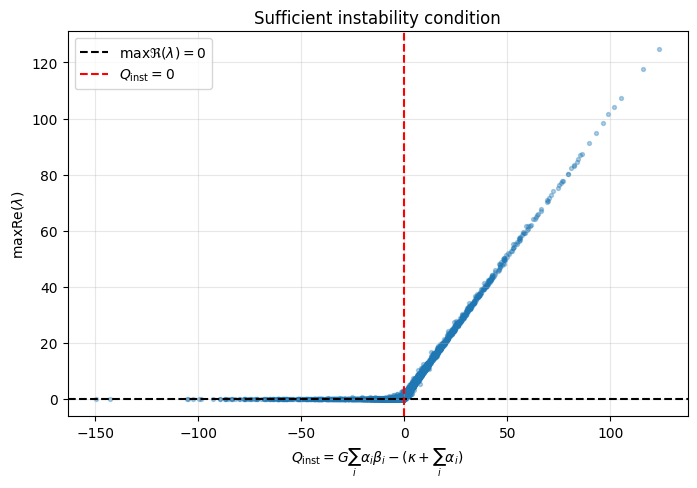

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(
    cloud["Q_inst"],
    cloud["max_real_eig"],
    s=8,
    alpha=0.35,
)

plt.axhline(0, color="black", linestyle="--", label=r"$\max \Re(\lambda)=0$")
plt.axvline(0, color="red", linestyle="--", label=r"$Q_{\rm inst}=0$")

plt.xlabel(r"$Q_{\rm inst}=G\sum_i \alpha_i\beta_i-(\kappa+\sum_i\alpha_i)$")
plt.ylabel(r"$\max \operatorname{Re}(\lambda)$")
plt.title("Sufficient instability condition")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [21]:
mask_inst_condition = cloud["Q_inst"] > 0
violations_inst = np.sum(cloud["max_real_eig"][mask_inst_condition] <= 0)

print("Number of points with Q_inst > 0:", np.sum(mask_inst_condition))
print("Violations of sufficient instability condition:", violations_inst)

Number of points with Q_inst > 0: 2832
Violations of sufficient instability condition: 0


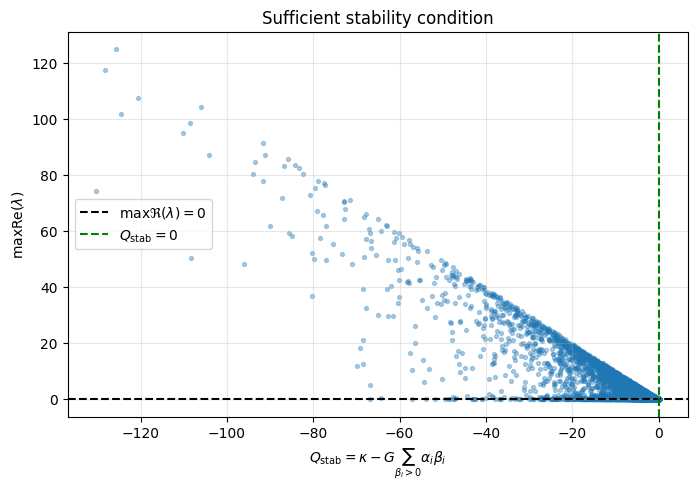

In [23]:
plt.figure(figsize=(8, 5))

plt.scatter(
    cloud["Q_stab"],
    cloud["max_real_eig"],
    s=8,
    alpha=0.35,
)

plt.axhline(0, color="black", linestyle="--", label=r"$\max \Re(\lambda)=0$")
plt.axvline(0, color="green", linestyle="--", label=r"$Q_{\rm stab}=0$")

plt.xlabel(r"$Q_{\rm stab}=\kappa-G\sum_{\beta_i>0}\alpha_i\beta_i$")
plt.ylabel(r"$\max \operatorname{Re}(\lambda)$")
plt.title("Sufficient stability condition")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [25]:
mask_stab_condition = cloud["Q_stab"] > 0
violations_stab = np.sum(cloud["max_real_eig"][mask_stab_condition] >= 0)

print("Number of points with Q_stab > 0:", np.sum(mask_stab_condition))
print("Violations of sufficient stability condition:", violations_stab)

Number of points with Q_stab > 0: 626
Violations of sufficient stability condition: 0
